# Notebook 3: Training CNN untuk 14 Encoding

Notebook ini melatih satu CNN untuk tiap encoding dengan pengaturan yang sama persis (arsitektur, optimizer, learning rate, batch, epoch, seed, dan split), mengikuti Rahadian et al. (2023). Tidak ada tuning khusus per encoding. Hasilnya: tabel akurasi (analog Tabel 9 paper), kurva training, confusion matrix, waktu training (analog Tabel 14), dan bobot model untuk Grad-CAM di Tahap 4.

Jalankan setelah Notebook 2. Training seluruhnya memakan waktu sekitar 10 sampai 15 menit.

## 1. Persiapan

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from pathlib import Path
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

SEED, IMG, BATCH, EPOCHS, LR = 42, 150, 20, 20, 1e-3
DEV = 'mps' if torch.backends.mps.is_available() else 'cpu'
ROOT = Path('..')
PROC, FIG, RES, MODELS = ROOT/'data/processed', ROOT/'figures', ROOT/'results', ROOT/'models'
MODELS.mkdir(exist_ok=True)

mats = np.load(PROC/'matriks_encoding.npz')
y_all = mats['y']
KEYS = [k for k in mats.files if k != 'y']
NAMES = [k.replace('_', ' ') for k in KEYS]
meta = pd.read_csv(PROC/'segmen_meta.csv')
N = len(meta)
split_all = np.r_[meta.split.values, meta.split.values]       # sepasang segmen selalu di split yang sama
idx = {s: np.where(split_all == s)[0] for s in ['train', 'val', 'test']}
print('Perangkat:', DEV, '| encoding:', len(KEYS))
print({s: len(v) for s, v in idx.items()}, '(gambar; separuhnya normal, separuhnya anomali)')

Perangkat: mps | encoding: 14
{'train': 1720, 'val': 368, 'test': 370} (gambar; separuhnya normal, separuhnya anomali)


## 2. Membuat gambar

Gambar dibuat dari matriks seperti di Notebook 2 (colormap `rainbow`, `origin='lower'`, 150 x 150 piksel). Rentang warna: GAF [-1, 1], MTF [0, 1]. Nilai piksel dibagi 255 sebelum masuk ke CNN.

In [2]:
cmap = plt.get_cmap('rainbow')
pix = (np.arange(IMG) * 20) // IMG

def to_image(mats_, vmin, vmax):
    scaled = np.clip((mats_ - vmin) / (vmax - vmin), 0, 1)
    rgb = (cmap(scaled)[..., :3] * 255).astype(np.uint8)[:, ::-1]
    return rgb[:, pix][:, :, pix]

def build_images(key):
    M = mats[key]
    vr = (-1, 1) if key.startswith('GA') else (0, 1)
    imgs = np.concatenate([to_image(M[s:s+500], *vr) for s in range(0, len(M), 500)])
    return torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous()

## 3. Arsitektur CNN

Sama dengan paper: tiga blok Conv2D (16, 32, 64 filter, kernel 3 x 3, ReLU) masing-masing diikuti max pooling 2 x 2, lalu Dense 512 (ReLU) dan satu unit output. Pada paper output memakai sigmoid. Di sini model mengeluarkan nilai mentah (logit) dan sigmoid digabung ke fungsi loss (`BCEWithLogitsLoss`), yang secara matematis sama dengan sigmoid ditambah binary cross-entropy tetapi lebih stabil secara numerik.

Optimizer RMSprop dengan learning rate 0,001. Parameter RMSprop lain disamakan dengan default Keras (`alpha=0.9`, `eps=1e-7`), karena paper memakai Keras. Batch 20, 20 epoch.

In [3]:
def block(i, o):
    return [nn.Conv2d(i, o, 3), nn.ReLU(), nn.MaxPool2d(2)]

def make_model():
    return nn.Sequential(*block(3, 16), *block(16, 32), *block(32, 64),
                         nn.Flatten(), nn.Linear(64 * 17 * 17, 512), nn.ReLU(), nn.Linear(512, 1))

print(make_model())
print('Jumlah parameter:', sum(p.numel() for p in make_model().parameters()))

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=18496, out_features=512, bias=True)
  (11): ReLU()
  (12): Linear(in_features=512, out_features=1, bias=True)
)
Jumlah parameter: 9494561


## 4. Fungsi training dan evaluasi

Untuk tiap encoding: model dibuat ulang dengan seed yang sama (bobot awal identik), urutan data di tiap epoch diacak dengan seed yang sama, dan model yang dipakai untuk evaluasi test adalah model setelah epoch ke-20 (tidak ada pemilihan model terbaik berdasarkan data validasi atau test). Akurasi train pada tabel dihitung ulang setelah training selesai dengan seluruh data train. Kurva training memakai nilai rata-rata selama epoch berjalan, seperti log Keras.

In [4]:
lossf = nn.BCEWithLogitsLoss()

def evaluate(model, X, yt):
    model.eval()
    logits = []
    with torch.no_grad():
        for s in range(0, len(X), 100):
            logits.append(model(X[s:s+100].float() / 255).squeeze(1))
    lo = torch.cat(logits)
    loss = lossf(lo, yt).item()
    p = torch.sigmoid(lo).cpu().numpy()
    return loss, float(((p > 0.5) == yt.cpu().numpy().astype(bool)).mean()), p

def train_encoding(key):
    X = build_images(key)
    Xtr, Xva, Xte = (X[idx[s]].to(DEV) for s in ['train', 'val', 'test'])
    ytr, yva, yte = (torch.tensor(y_all[idx[s]], dtype=torch.float32, device=DEV) for s in ['train', 'val', 'test'])

    torch.manual_seed(SEED)
    model = make_model().to(DEV)
    opt = torch.optim.RMSprop(model.parameters(), lr=LR, alpha=0.9, eps=1e-7)
    g = torch.Generator().manual_seed(SEED)

    hist = []
    t0 = time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        sl = sc = 0.0
        for s in range(0, len(Xtr), BATCH):
            i = perm[s:s+BATCH].to(DEV)
            lo = model(Xtr[i].float() / 255).squeeze(1)
            loss = lossf(lo, ytr[i])
            opt.zero_grad(); loss.backward(); opt.step()
            sl += loss.item() * len(i); sc += ((lo > 0) == (ytr[i] > 0.5)).sum().item()
        vl, va, _ = evaluate(model, Xva, yva)
        hist.append(dict(epoch=ep, train_loss=sl / len(Xtr), train_acc=sc / len(Xtr), val_loss=vl, val_acc=va))
    t_train = time.perf_counter() - t0

    _, tr_acc, _ = evaluate(model, Xtr, ytr)
    _, va_acc, _ = evaluate(model, Xva, yva)
    te_loss, te_acc, p_te = evaluate(model, Xte, yte)
    yt = y_all[idx['test']]; pred = (p_te > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, MODELS/f'{key}.pt')
    res = dict(encoding=key.replace('_', ' '), train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
               precision=precision_score(yt, pred, zero_division=0), recall=recall_score(yt, pred, zero_division=0),
               f1=f1_score(yt, pred, zero_division=0), tn=tn, fp=fp, fn=fn, tp=tp, waktu_training_detik=t_train)
    return res, pd.DataFrame(hist).assign(encoding=key.replace('_', ' ')), p_te

## 5. Menjalankan training untuk 14 encoding

In [5]:
results, histories, probs = [], [], {}
for key in KEYS:
    r, h, p = train_encoding(key)
    results.append(r); histories.append(h); probs[r['encoding']] = p
    print(f"{r['encoding']:16s} train {r['train_acc']*100:5.1f}%  val {r['val_acc']*100:5.1f}%  test {r['test_acc']*100:5.1f}%  waktu {r['waktu_training_detik']:.0f} s")
res = pd.DataFrame(results)
hist = pd.concat(histories, ignore_index=True)
hist.round(4).to_csv(RES/'riwayat_training.csv', index=False)

GADF             train 100.0%  val  97.3%  test  97.8%  waktu 44 s


GASF             train 100.0%  val  97.6%  test  97.3%  waktu 45 s


MTF Uniform 2    train  97.1%  val  84.2%  test  82.2%  waktu 42 s


MTF Uniform 4    train  99.6%  val  89.4%  test  85.7%  waktu 44 s


MTF Uniform 5    train  99.9%  val  92.1%  test  92.7%  waktu 43 s


MTF Uniform 10   train 100.0%  val  91.6%  test  90.8%  waktu 39 s


... (4 outputs left out)

MTF Normal 2     train  81.6%  val  77.7%  test  76.8%  waktu 41 s


MTF Normal 4     train  91.1%  val  83.4%  test  80.5%  waktu 39 s


MTF Normal 5     train  90.9%  val  80.4%  test  79.5%  waktu 41 s


MTF Normal 10    train  96.2%  val  78.5%  test  75.4%  waktu 40 s


## 6. Tabel akurasi (analog Tabel 9 paper)

Akurasi train, validasi, dan test, serta precision, recall, dan F1 di data test. Kelas "anomali" dianggap kelas positif.

In [6]:
cols = ['encoding', 'train_acc', 'val_acc', 'test_acc', 'precision', 'recall', 'f1', 'tn', 'fp', 'fn', 'tp', 'waktu_training_detik']
tab = res[cols].copy()
for c in ['train_acc', 'val_acc', 'test_acc']:
    tab[c] = (tab[c] * 100).round(1)
for c in ['precision', 'recall', 'f1']:
    tab[c] = tab[c].round(3)
tab['waktu_training_detik'] = tab.waktu_training_detik.round(1)
tab.to_csv(RES/'akurasi_encoding.csv', index=False)

yt = y_all[idx['test']]
ids = pd.DataFrame({'gambar_id': idx['test'], 'segmen_id': idx['test'] % N, 'kelas': yt})
pd.concat([ids, pd.DataFrame({k: v.round(4) for k, v in probs.items()})], axis=1).to_csv(RES/'prediksi_test.csv', index=False)
tab

,encoding,train_acc,val_acc,test_acc,precision,recall,f1,tn,fp,fn,tp,waktu_training_detik
0,GADF,100.0,97.3,97.8,0.973,0.984,0.978,180,5,3,182,44.2
1,GASF,100.0,97.6,97.3,0.973,0.973,0.973,180,5,5,180,44.7
2,MTF Uniform 2,97.1,84.2,82.2,0.829,0.811,0.820,154,31,35,150,42.0
3,MTF Uniform 4,99.6,89.4,85.7,0.827,0.903,0.863,150,35,18,167,43.7
4,MTF Uniform 5,99.9,92.1,92.7,0.939,0.914,0.926,174,11,16,169,43.0
5,MTF Uniform 10,100.0,91.6,90.8,0.927,0.886,0.906,172,13,21,164,38.8
6,MTF Quantile 2,80.1,67.9,64.6,0.665,0.589,0.625,130,55,76,109,38.6
7,MTF Quantile 4,96.1,70.4,70.8,0.723,0.676,0.698,137,48,60,125,39.9
8,MTF Quantile 5,97.3,70.4,64.6,0.650,0.632,0.641,122,63,68,117,40.8
9,MTF Quantile 10,98.5,57.1,56.5,0.564,0.573,0.568,103,82,79,106,41.3


## 7. Kurva training

Kiri: akurasi, kanan: loss. Garis biru untuk data train dan oranye untuk data validasi. Tiap panel satu encoding.

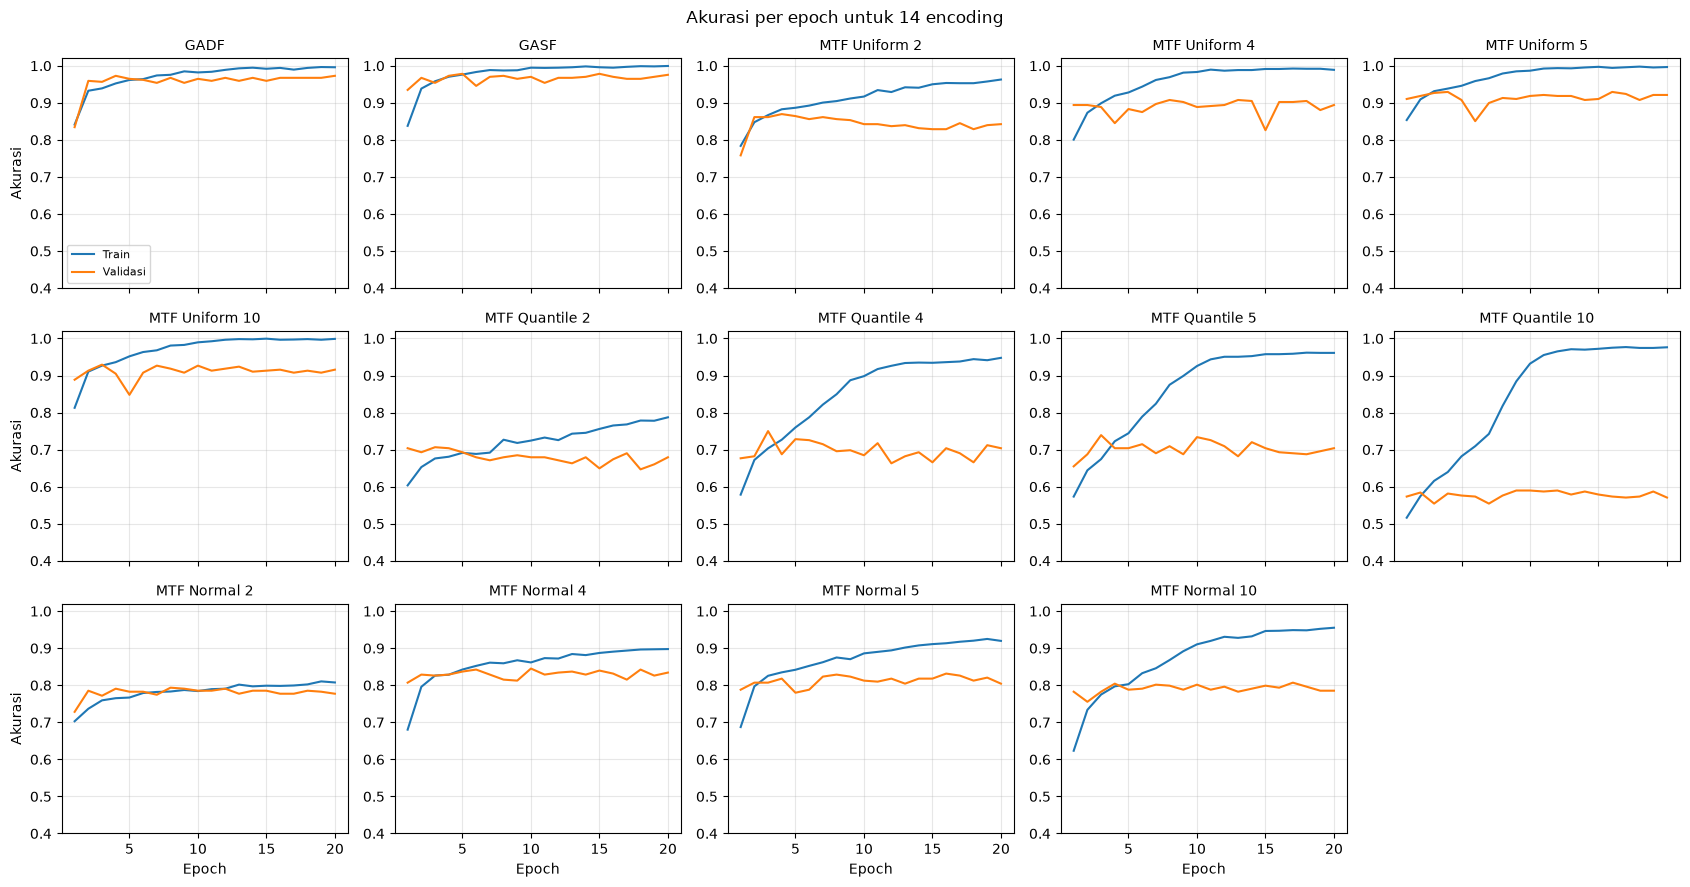

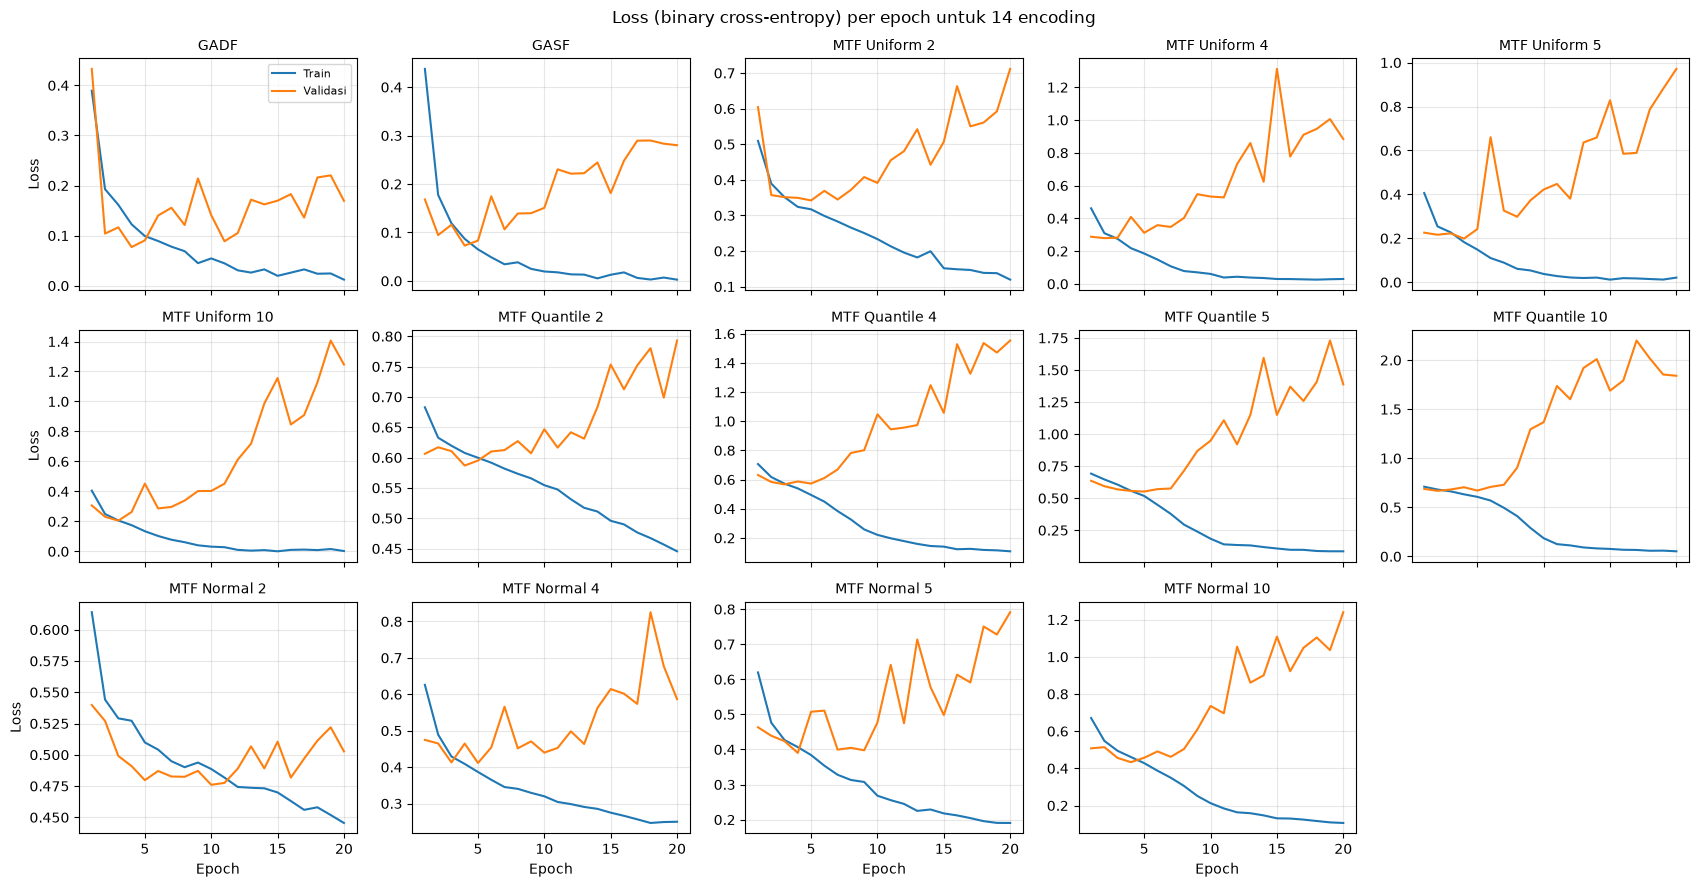

In [7]:
def curve_grid(cols_pair, ylabel, fname, title, ylim=None):
    fig, axes = plt.subplots(3, 5, figsize=(17, 9), sharex=True)
    for ax, nm in zip(axes.ravel(), NAMES):
        h = hist[hist.encoding == nm]
        ax.plot(h.epoch, h[cols_pair[0]], label='Train'); ax.plot(h.epoch, h[cols_pair[1]], label='Validasi')
        ax.set_title(nm, fontsize=10); ax.grid(alpha=0.3)
        if ylim: ax.set_ylim(*ylim)
    for ax in axes.ravel()[len(NAMES):]:
        ax.axis('off')
    for ax in axes[-1]: ax.set_xlabel('Epoch')
    for ax in axes[:, 0]: ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG/fname, dpi=150); plt.show()

curve_grid(['train_acc', 'val_acc'], 'Akurasi', '09_kurva_akurasi.png', 'Akurasi per epoch untuk 14 encoding', ylim=(0.4, 1.02))
curve_grid(['train_loss', 'val_loss'], 'Loss', '10_kurva_loss.png', 'Loss (binary cross-entropy) per epoch untuk 14 encoding')

## 8. Confusion matrix: encoding terbaik dan terburuk

Dipilih berdasarkan akurasi test (jika seri, yang F1-nya lebih tinggi dipilih sebagai terbaik).

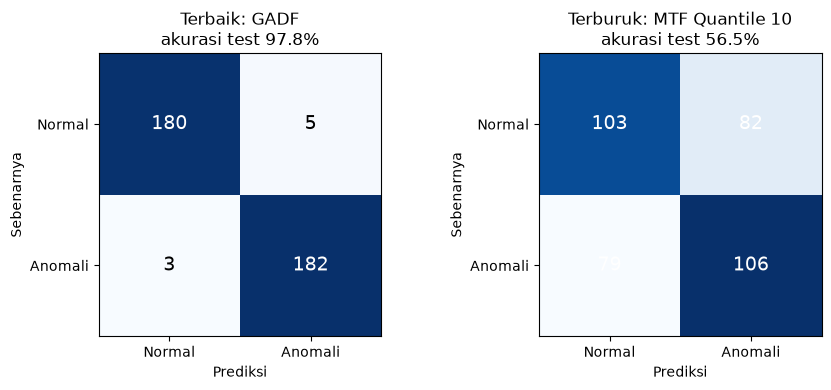

Terbaik: GADF | terburuk: MTF Quantile 10


In [8]:
order = res.sort_values(['test_acc', 'f1'], ascending=[False, False])
best, worst = order.iloc[0], order.iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, r, lab in zip(axes, [best, worst], ['Terbaik', 'Terburuk']):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.sum(axis=1).max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14, color='white' if cm[i, j] > cm.sum(axis=1).max() / 2 else 'black')
    ax.set_xticks([0, 1], ['Normal', 'Anomali']); ax.set_yticks([0, 1], ['Normal', 'Anomali'])
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya')
    ax.set_title(f'{lab}: {r.encoding}\nakurasi test {r.test_acc*100:.1f}%')
fig.tight_layout(); fig.savefig(FIG/'11_confusion_matrix.png', dpi=150); plt.show()
print('Terbaik:', best.encoding, '| terburuk:', worst.encoding)

## 9. Pemeriksaan kewajaran

Beberapa hal yang dicek sebelum hasil dipakai: sebaran akurasi test antar encoding, selisih antara akurasi train dan test (untuk mendeteksi overfitting atau kebocoran data), dan apakah ada encoding yang tidak belajar sama sekali.

In [9]:
res['gap_train_test'] = (res.train_acc - res.test_acc) * 100
print(f"Akurasi test: min {res.test_acc.min()*100:.1f}% | maks {res.test_acc.max()*100:.1f}% | SD antar encoding {res.test_acc.std()*100:.1f} poin")
print('Encoding dengan akurasi test >= 98%:', int((res.test_acc >= 0.98).sum()), 'dari', len(res))
print('Encoding dengan akurasi test <= 55%:', list(res.encoding[res.test_acc <= 0.55]))
print(f"Selisih train dikurangi test (poin): min {res.gap_train_test.min():.1f}, maks {res.gap_train_test.max():.1f}")
print('Encoding dengan test lebih tinggi dari train lebih dari 3 poin:', list(res.encoding[res.gap_train_test < -3]))
print('Encoding dengan train lebih tinggi dari test lebih dari 5 poin:', list(res.encoding[res.gap_train_test > 5]))
res[['encoding', 'train_acc', 'val_acc', 'test_acc', 'gap_train_test']].round(3)

Akurasi test: min 56.5% | maks 97.8% | SD antar encoding 12.6 poin
Encoding dengan akurasi test >= 98%: 0 dari 14
Encoding dengan akurasi test <= 55%: []
Selisih train dikurangi test (poin): min 2.2, maks 42.0
Encoding dengan test lebih tinggi dari train lebih dari 3 poin: []
Encoding dengan train lebih tinggi dari test lebih dari 5 poin: ['MTF Uniform 2', 'MTF Uniform 4', 'MTF Uniform 5', 'MTF Uniform 10', 'MTF Quantile 2', 'MTF Quantile 4', 'MTF Quantile 5', 'MTF Quantile 10', 'MTF Normal 4', 'MTF Normal 5', 'MTF Normal 10']


,encoding,train_acc,val_acc,test_acc,gap_train_test
0,GADF,1.000,0.973,0.978,2.162
1,GASF,1.000,0.976,0.973,2.703
2,MTF Uniform 2,0.971,0.842,0.822,14.931
3,MTF Uniform 4,0.996,0.894,0.857,13.917
4,MTF Uniform 5,0.999,0.921,0.927,7.239
5,MTF Uniform 10,1.000,0.916,0.908,9.189
6,MTF Quantile 2,0.801,0.679,0.646,15.464
7,MTF Quantile 4,0.961,0.704,0.708,25.294
8,MTF Quantile 5,0.973,0.704,0.646,32.731
9,MTF Quantile 10,0.985,0.571,0.565,42.002


## 10. MTF Normal: hubungan akurasi dengan gambar seragam

Di Notebook 2 terlihat sebagian gambar MTF Normal berwarna seragam (satu warna merah penuh), dan lebih sering terjadi pada segmen normal. Gambar seragam tidak membawa informasi apa pun, kecuali bahwa gambar semacam itu lebih sering berasal dari segmen normal. Tabel berikut membandingkan akurasi test dengan jumlah gambar seragam di data test, dan batas atas akurasi jika CNN sempurna pada gambar yang tidak seragam tetapi hanya menebak kelas terbanyak untuk gambar yang seragam.

In [10]:
rows = []
mtfn = pd.read_csv(RES/'mtf_normal_seragam.csv').set_index('n_bins')
te_idx = idx['test']
for b in [2, 4, 5, 10]:
    key = f'MTF_Normal_{b}'; nm = key.replace('_', ' ')
    M = mats[key][te_idx].reshape(len(te_idx), -1)
    uni = M.std(axis=1) == 0
    pred = (probs[nm] > 0.5).astype(int)
    ok = pred == yt
    n_un, n_nu = uni.sum(), (~uni).sum()
    maj = max((yt[uni] == 0).sum(), (yt[uni] == 1).sum()) if n_un else 0
    rows.append({'encoding': nm,
                 'persen_seragam_segmen_normal': mtfn.loc[b, 'persen_gambar_seragam_normal_terstandar'],
                 'persen_seragam_segmen_anomali': mtfn.loc[b, 'persen_gambar_seragam_anomali_terstandar'],
                 'gambar_seragam_di_test': int(n_un),
                 'dari_itu_normal': int((yt[uni] == 0).sum()),
                 'akurasi_pada_seragam': round(100 * ok[uni].mean(), 1) if n_un else np.nan,
                 'akurasi_pada_tidak_seragam': round(100 * ok[~uni].mean(), 1),
                 'akurasi_test_total': round(100 * ok.mean(), 1),
                 'batas_atas_akurasi': round(100 * (n_nu + maj) / len(yt), 1)})
mtfn_acc = pd.DataFrame(rows)
mtfn_acc.to_csv(RES/'mtf_normal_akurasi.csv', index=False)
mtfn_acc

,encoding,persen_seragam_segmen_normal,persen_seragam_segmen_anomali,gambar_seragam_di_test,dari_itu_normal,akurasi_pada_seragam,akurasi_pada_tidak_seragam,akurasi_test_total,batas_atas_akurasi
0,MTF Normal 2,66.8,19.0,149,120,80.5,74.2,76.8,92.2
1,MTF Normal 4,31.2,6.7,59,51,86.4,79.4,80.5,97.8
2,MTF Normal 5,22.7,5.4,50,43,86.0,78.4,79.5,98.1
3,MTF Normal 10,8.5,2.5,18,14,77.8,75.3,75.4,98.9


## 11. Waktu per tahap (analog Tabel 14 paper)

Waktu encoding dan konversi gambar diambil dari Notebook 2, waktu training dari notebook ini. Penghematan waktu dihitung seperti di paper: jika memilih encoding hanya dari statistik matriks (tanpa membuat gambar dan melatih CNN), waktu konversi gambar dan training tidak diperlukan.

In [11]:
w2 = pd.read_csv(RES/'waktu_encoding.csv')
w = w2.merge(res[['encoding', 'waktu_training_detik']], on='encoding')
w['total_detik'] = w.matriks_detik + w.gambar_detik + w.waktu_training_detik
w['hemat_detik'] = w.gambar_detik + w.waktu_training_detik
w['hemat_persen'] = 100 * w.hemat_detik / w.total_detik
w.loc[len(w)] = ['Rata-rata'] + list(w.iloc[:, 1:].mean())
w.round(3).to_csv(RES/'waktu_per_tahap.csv', index=False)
w.round(3)

,encoding,matriks_detik,gambar_detik,total_detik,waktu_training_detik,hemat_detik,hemat_persen
0,GADF,0.003,0.192,44.348,44.153,44.345,99.993
1,GASF,0.003,0.175,44.920,44.742,44.917,99.993
2,MTF Uniform 2,0.003,0.181,42.209,42.025,42.206,99.993
3,MTF Uniform 4,0.003,0.178,43.890,43.709,43.887,99.993
4,MTF Uniform 5,0.003,0.176,43.141,42.962,43.138,99.993
5,MTF Uniform 10,0.004,0.177,38.949,38.768,38.945,99.990
6,MTF Quantile 2,0.004,0.178,38.817,38.635,38.813,99.990
7,MTF Quantile 4,0.005,0.183,40.130,39.942,40.125,99.988
8,MTF Quantile 5,0.005,0.212,40.990,40.773,40.985,99.988
9,MTF Quantile 10,0.009,0.225,41.504,41.270,41.495,99.978
